In [ ]:
# Nesse ESA, nós vamos programas o modelo HBV (versão simplificada/educacional)
# O Modelo (visto em aula) funciona através de 4 módulos: 1) Derretimento/acúmulo de neve;
# 2) Umidade do solo e chuva efetiva
# 3) Evapotranspiração
# 4) Escoamentos

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pandas as pd

In [ ]:
# Primeiro vamos definir os parâmetros do modelo e os dados de entrada

# Abaixo vamos definir intervalos de valores para cada parâmetro para poder fazer as análises de sensibilidade
n_int = 10
DDs = np.linspace(3.,7.,n_int)
FCs = np.linspace(100.,200.,n_int)
Betas = np.linspace(1.,7.,n_int)
Cs = np.linspace(0.01,0.07,n_int)
K_0s = np.linspace(0.05,0.2,n_int)
Ls = np.linspace(2.,5.,n_int)
K_1s = np.linspace(0.01,0.1,n_int)
K_2s = np.linspace(0.01,0.05,n_int)
K_ps = np.linspace(0.01,0.05,n_int)
PWPs = np.linspace(90.,180.,n_int)

# Agora vamos definir mais alguns parâmetros fixos
Tt = 0. # Temperatura abaixo da qual consideraremos a chuva como sendo somente neve
A = 1027. # Area da bacia em km2
SM = 100. # Umidade do solo inicial (mm)
S_1 = 3. # Volume inicial do reservatório 1 (superficial e sub-superficial) (mm)
S_2 = 10. # Volume inicial do reservatório 2 (subterrâneo) (mm)

# 1. Lendo os dados brutos de Jaguari diretamente
df = pd.read_csv('Forcantes_Jaguari.txt', sep='\t')
df['date'] = pd.to_datetime(df['date'])

# Tratando os dados faltantes (NA) na vazão com interpolação
df['Qobs'] = pd.to_numeric(df['Qobs'], errors='coerce').interpolate(method='linear')

# 2. Extraindo os vetores para o modelo HBV rodar (P, T, Qobs, mes)
P = df['P'].values
T = df['temp'].values
Qobs = df['Qobs'].values
mes = df['date'].dt.month.values

# 3. Calculando as médias mensais (Tm e PEm) dinamicamente a partir dos dados
monthly_stats = df.groupby(df['date'].dt.month).agg(
    monthly_temp=('temp', 'mean'),
    monthly_pet=('PET', 'mean')
)
Tm = monthly_stats['monthly_temp'].values
PEm = monthly_stats['monthly_pet'].values

print("Dados de Jaguari carregados com sucesso direto no Python!")
print(f"Total de dias: {len(P)}")

Dados de Jaguari carregados com sucesso direto no Python!
Total de dias: 9497


In [ ]:
print(Tm.shape)

(12,)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


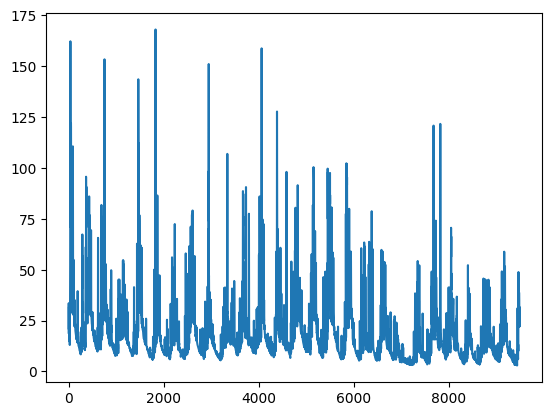

In [ ]:
plt.plot(Qobs)

In [ ]:
import numpy as np

# Definição de parâmetros fixos
DD = DDs[n_int-1]
FC = FCs[n_int-1]
Beta = Betas[n_int-1]
C = Cs[n_int-1]
K_0 = K_0s[n_int-1]
L = Ls[n_int-1]
K_1 = K_1s[n_int-1]
K_2 = K_2s[n_int-1]
K_p = K_ps[n_int-1]
PWP = PWPs[n_int-1]

# Inicialização das variáveis
n = len(P)
neve = np.zeros(n)
umidade_solo = np.zeros(n)
umidade_solo[0] = SM
Q0s, Q1s, Q2s = np.zeros((3, n))
S_1s, S_2s = np.zeros((2, n))
S_1s[0], S_2s[0] = S_1, S_2

# Loop temporal
for idia in range(1, n):
    T_atual = T[idia]
    P_atual = P[idia]
    S1_anterior = S_1s[idia-1]
    S2_anterior = S_2s[idia-1]
    umidade_anterior = umidade_solo[idia-1]
    neve_anterior = neve[idia-1]

    if T_atual <= Tt:
        Sm, Peff, P_solo = 0, 0, 0
        neve[idia] = neve_anterior + P_atual
    else:
        Sm = min(neve_anterior, DD * (T_atual - Tt))
        neve[idia] = neve_anterior - Sm
        Peff = ((umidade_anterior / FC) ** Beta) * (P_atual + Sm)
        P_solo = P_atual

    PEa = (1 + C * (T_atual - Tm[int(mes[idia]-1)])) * PEm[int(mes[idia]-1)]
    Ea = PEa * (umidade_anterior / PWP) if umidade_anterior < PWP else PEa

    umidade_solo[idia] = max(0, umidade_anterior + P_solo - Peff - Ea)

    # Cálculo das vazões
    if S1_anterior > L:
        Q0s[idia] = K_0 * (S1_anterior - L) * A * 1000 / (24 * 3600)

    Q1s[idia] = K_1 * S1_anterior * A * 1000 / (24 * 3600)
    Q2s[idia] = K_2 * S2_anterior * A * 1000 / (24 * 3600)

    S_1s[idia] = max(0, S1_anterior + Peff - (S1_anterior - L) * K_0 - S1_anterior * (K_1 + K_p))
    S_2s[idia] = max(0, S2_anterior + S1_anterior * K_p - S2_anterior * K_2)

# Soma final das vazões
Q = Q0s + Q1s + Q2s


In [ ]:
'''
# Agora vamos começar a programar o modelo em si considerando
# apenas 1 valor dos parâmetros do modelo (célula anterior)
DD = DDs[n_int-1]
FC = FCs[n_int-1]
Beta = Betas[n_int-1]
C = Cs[n_int-1]
K_0 = K_0s[n_int-1]
L = Ls[n_int-1]
K_1 = K_1s[n_int-1]
K_2 = K_2s[n_int-1]
K_p = K_ps[n_int-1]
PWP = PWPs[n_int-1]

# Variáveis que irão armazenar a evolução do acumulado de neve e da umidade do solo
neve = np.zeros(P.shape)
umidade_solo = np.zeros(P.shape)
umidade_solo[0] = SM

# Variáveis que irão armazenar as vazões
Q0s = np.zeros(P.shape)
Q1s = np.zeros(P.shape)
Q2s = np.zeros(P.shape)

# Variáveis que irão armazenar os níveis dos reservatórios 1 e 2
S_1s = np.zeros(P.shape)
S_1s[0] = S_1
S_2s = np.zeros(P.shape)
S_2s[0] = S_2

# Loop nos dados diários
for idia in np.arange(1,len(P)):
    # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
    if T[idia]<=Tt:
        # Não haverá derretimento, portanto Sm = 0
        Sm = 0.

        # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
        neve[idia] = neve[idia-1] + P[idia]

        # Nesse caso não haverá chuva efetiva também
        Peff = 0.

        # Não haverá contribuição de P para a umidade do solo
        P_solo = 0.

    else:
        # Nesse caso haverá derretimento pela equação do modelo,
        # mas o derretimento não pode superar o nível do reservatório
        # de neve
        Sm = min(neve[idia-1],DD*(T[idia]-Tt))

        # Como derreteu, iremos reduzir o reservatório de neve
        neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

        # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
        Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

        # A chuva P poderá contribuir para a umidade do solo caso P>Peff
        P_solo = P[idia]

    # Agora vamos calcular a ET real
    # Primeiro ajusta a ET potencial em função da T do dia
    PEa = (1 + C*(T[idia] - Tm[int(mes[idia])]))*PEm[int(mes[idia])]
    # Agora sim calcula a ET real
    if umidade_solo[idia-1]<PWP:
        Ea = PEa*(umidade_solo[idia-1]/PWP)
    else:
        Ea = PEa

    # Ajusta a umidade do solo
    umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

    # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
    # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
    # A divisão por (24*3600) converte de dia-1 para s-1
    if S_1s[idia-1]>L:
        Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
    else:
        Q0s[idia] = 0.

    Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
    #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

    Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

    # Ajusta o nível do reservatório 1
    S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
    # Ajusta o nível do reservatório 2
    S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

# A vazão final será a soma das vazões superficial, sub-superficial e subterrânea
# Este será o resultado do modelo que devemos comparar com as observações
Q = Q0s + Q1s + Q2s
'''

'\n# Agora vamos começar a programar o modelo em si considerando\n# apenas 1 valor dos parâmetros do modelo (célula anterior)\nDD = DDs[n_int-1]\nFC = FCs[n_int-1]\nBeta = Betas[n_int-1]\nC = Cs[n_int-1]\nK_0 = K_0s[n_int-1]\nL = Ls[n_int-1]\nK_1 = K_1s[n_int-1]\nK_2 = K_2s[n_int-1]\nK_p = K_ps[n_int-1]\nPWP = PWPs[n_int-1]\n\n# Variáveis que irão armazenar a evolução do acumulado de neve e da umidade do solo\nneve = np.zeros(P.shape)\numidade_solo = np.zeros(P.shape)\numidade_solo[0] = SM\n\n# Variáveis que irão armazenar as vazões\nQ0s = np.zeros(P.shape)\nQ1s = np.zeros(P.shape)\nQ2s = np.zeros(P.shape)\n\n# Variáveis que irão armazenar os níveis dos reservatórios 1 e 2\nS_1s = np.zeros(P.shape)\nS_1s[0] = S_1\nS_2s = np.zeros(P.shape)\nS_2s[0] = S_2\n\n# Loop nos dados diários\nfor idia in np.arange(1,len(P)):\n    # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve\n    if T[idia]<=Tt:\n        # Não haverá derretimento, portanto Sm = 0\n        Sm = 0

Text(0, 0.5, 'Qsim (m3/s)')

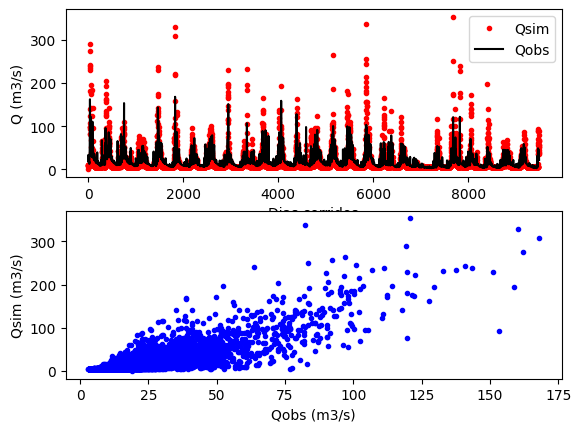

In [ ]:
plt.subplot(2,1,1)
plt.plot(Q,'r.', label='Qsim')
plt.plot(Qobs,'k-', label='Qobs')
plt.legend()
plt.xlabel('Dias corridos')
plt.ylabel('Q (m3/s)')

plt.subplot(2,1,2)
plt.plot(Qobs,Q,'b.')
plt.xlabel('Qobs (m3/s)')
plt.ylabel('Qsim (m3/s)')


In [ ]:
# Vamos estimar a qualidade da simulação baseado no RMSE (root mean squared error)
RMSE = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
NRMSE = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

print('RMSE ', RMSE)
print('NRMSE ', NRMSE)

RMSE  15.31991862623687
NRMSE  0.5105487111650704


9.681474745894237e-32
0.0


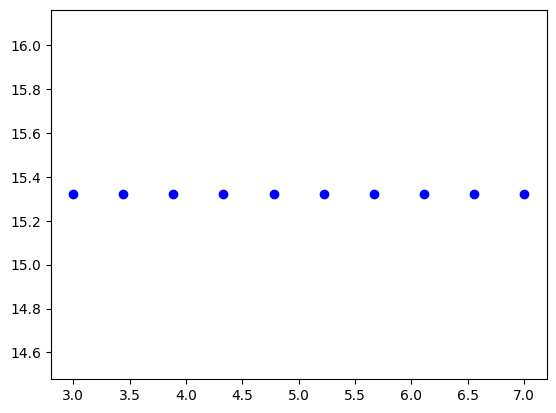

In [ ]:
################## DD

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_DD = np.zeros(DDs.shape)
NRMSEs_DD = np.zeros(DDs.shape)
Rns_DD = np.zeros(DDs.shape)
Rp_DD = np.zeros(DDs.shape)
erroabs_DD = np.zeros(DDs.shape)

# Loop nos DD
for idd in np.arange(len(DDs)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DDs[idd]*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_DD[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_DD[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_DD[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_DD[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_DD[idd] = (numerador_ea / denominador_ea) * 100

# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(DDs,RMSEs_DD,'bo')
sens_DD, intercept, r_value, p_value, std_err = linregress(DDs, RMSEs_DD)
sens_norm_DD, intercept, r_value, p_value, std_err = linregress(np.log(DDs), np.log(NRMSEs_DD))

print(sens_DD)
print(sens_norm_DD)

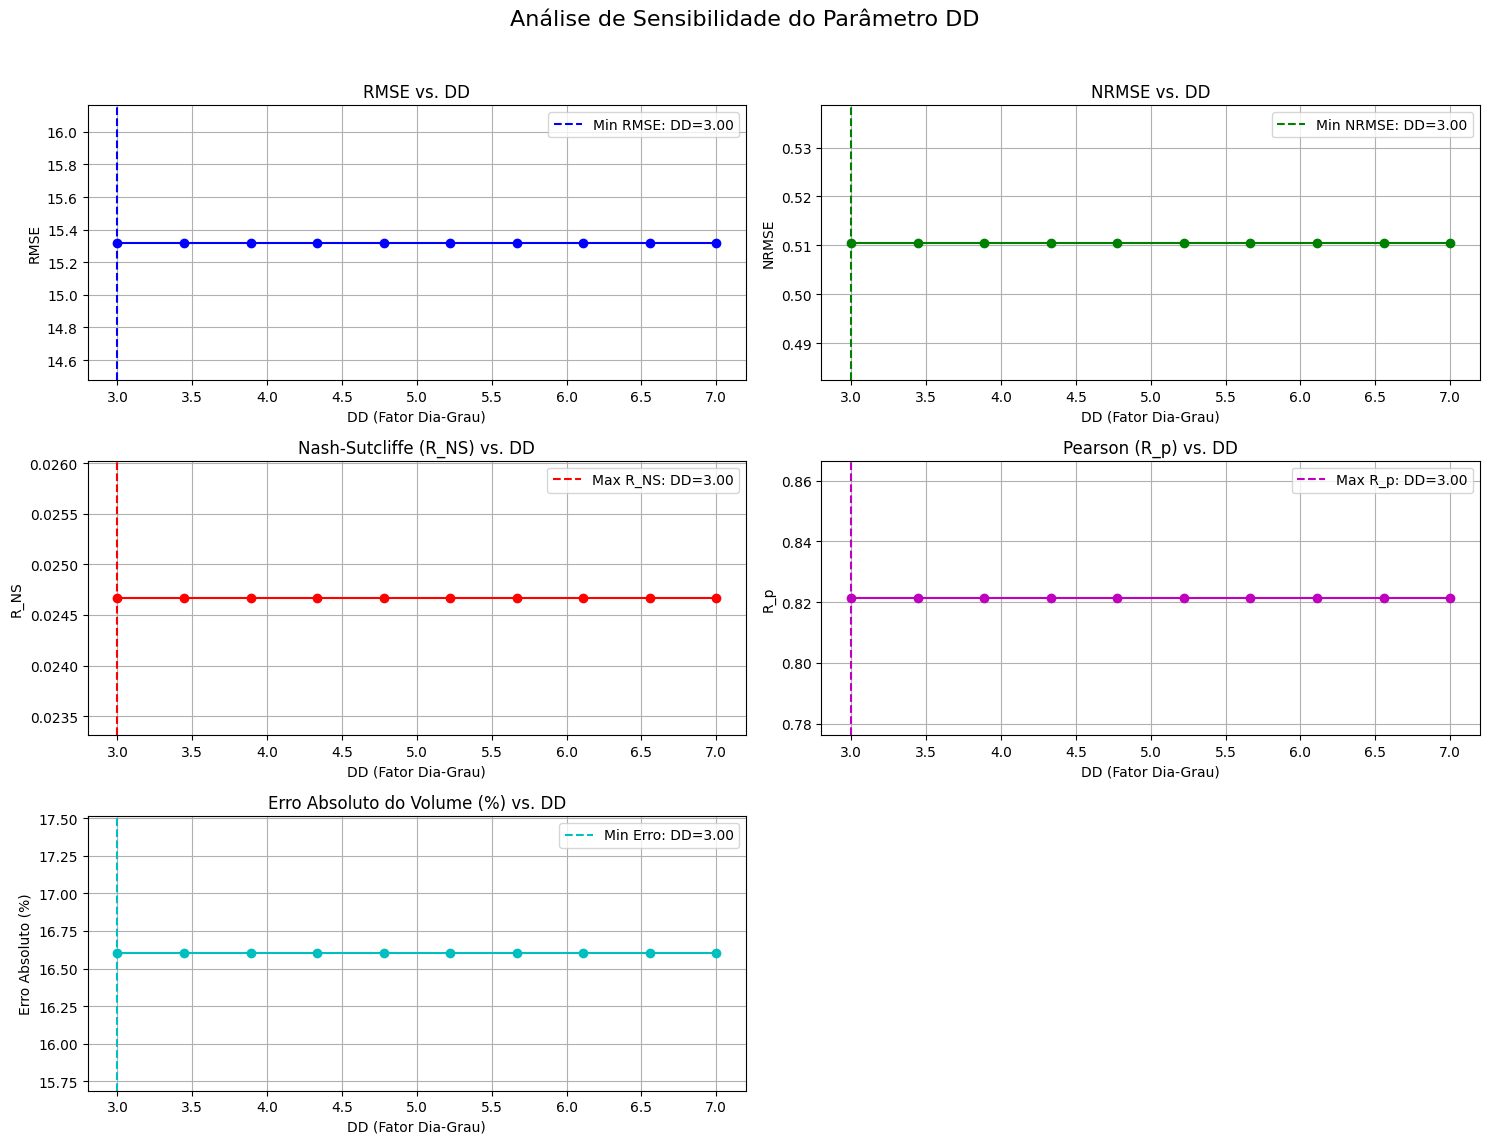

In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do DD ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro DD', fontsize=16)

# 1. RMSE vs DD
axs[0, 0].plot(DDs, RMSEs_DD, 'o-b')
axs[0, 0].set_title('RMSE vs. DD')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('DD (Fator Dia-Grau)')
axs[0, 0].axvline(x=DDs[np.argmin(RMSEs_DD)], color='b', linestyle='--', label=f'Min RMSE: DD={DDs[np.argmin(RMSEs_DD)]:.2f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs DD
axs[0, 1].plot(DDs, NRMSEs_DD, 'o-g')
axs[0, 1].set_title('NRMSE vs. DD')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('DD (Fator Dia-Grau)')
axs[0, 1].axvline(x=DDs[np.argmin(NRMSEs_DD)], color='g', linestyle='--', label=f'Min NRMSE: DD={DDs[np.argmin(NRMSEs_DD)]:.2f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs DD
axs[1, 0].plot(DDs, Rns_DD, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. DD')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('DD (Fator Dia-Grau)')
axs[1, 0].axvline(x=DDs[np.argmax(Rns_DD)], color='r', linestyle='--', label=f'Max R_NS: DD={DDs[np.argmax(Rns_DD)]:.2f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs DD
axs[1, 1].plot(DDs, Rp_DD, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. DD')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('DD (Fator Dia-Grau)')
axs[1, 1].axvline(x=DDs[np.argmax(Rp_DD)], color='m', linestyle='--', label=f'Max R_p: DD={DDs[np.argmax(Rp_DD)]:.2f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs DD
axs[2, 0].plot(DDs, erroabs_DD, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. DD')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('DD (Fator Dia-Grau)')
axs[2, 0].axvline(x=DDs[np.argmin(erroabs_DD)], color='c', linestyle='--', label=f'Min Erro: DD={DDs[np.argmin(erroabs_DD)]:.2f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

#DD = 3!

-0.16221097050472433
-1.0716048731464374


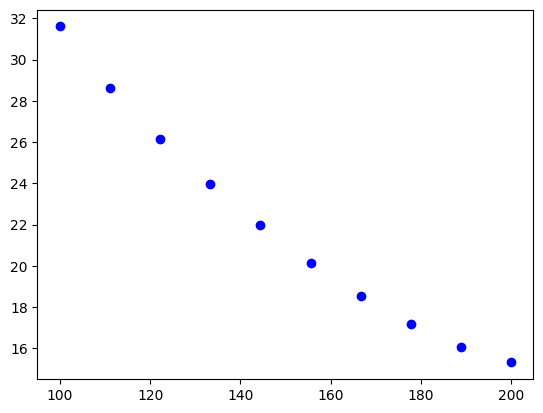

In [ ]:
################## FC

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_FC = np.zeros(FCs.shape)
NRMSEs_FC = np.zeros(FCs.shape)
Rns_FC = np.zeros(FCs.shape)
Rp_FC = np.zeros(FCs.shape)
erroabs_FC = np.zeros(FCs.shape)


# Loop nos FC
for idd in np.arange(len(FCs)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FCs[idd])**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_FC[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_FC[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_FC[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_FC[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_FC[idd] = (numerador_ea / denominador_ea) * 100


# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(FCs,RMSEs_FC,'bo')
sens_FC, intercept, r_value, p_value, std_err = linregress(FCs, RMSEs_FC)
sens_norm_FC, intercept, r_value, p_value, std_err = linregress(np.log(FCs), np.log(RMSEs_FC))

print(sens_FC)
print(sens_norm_FC)

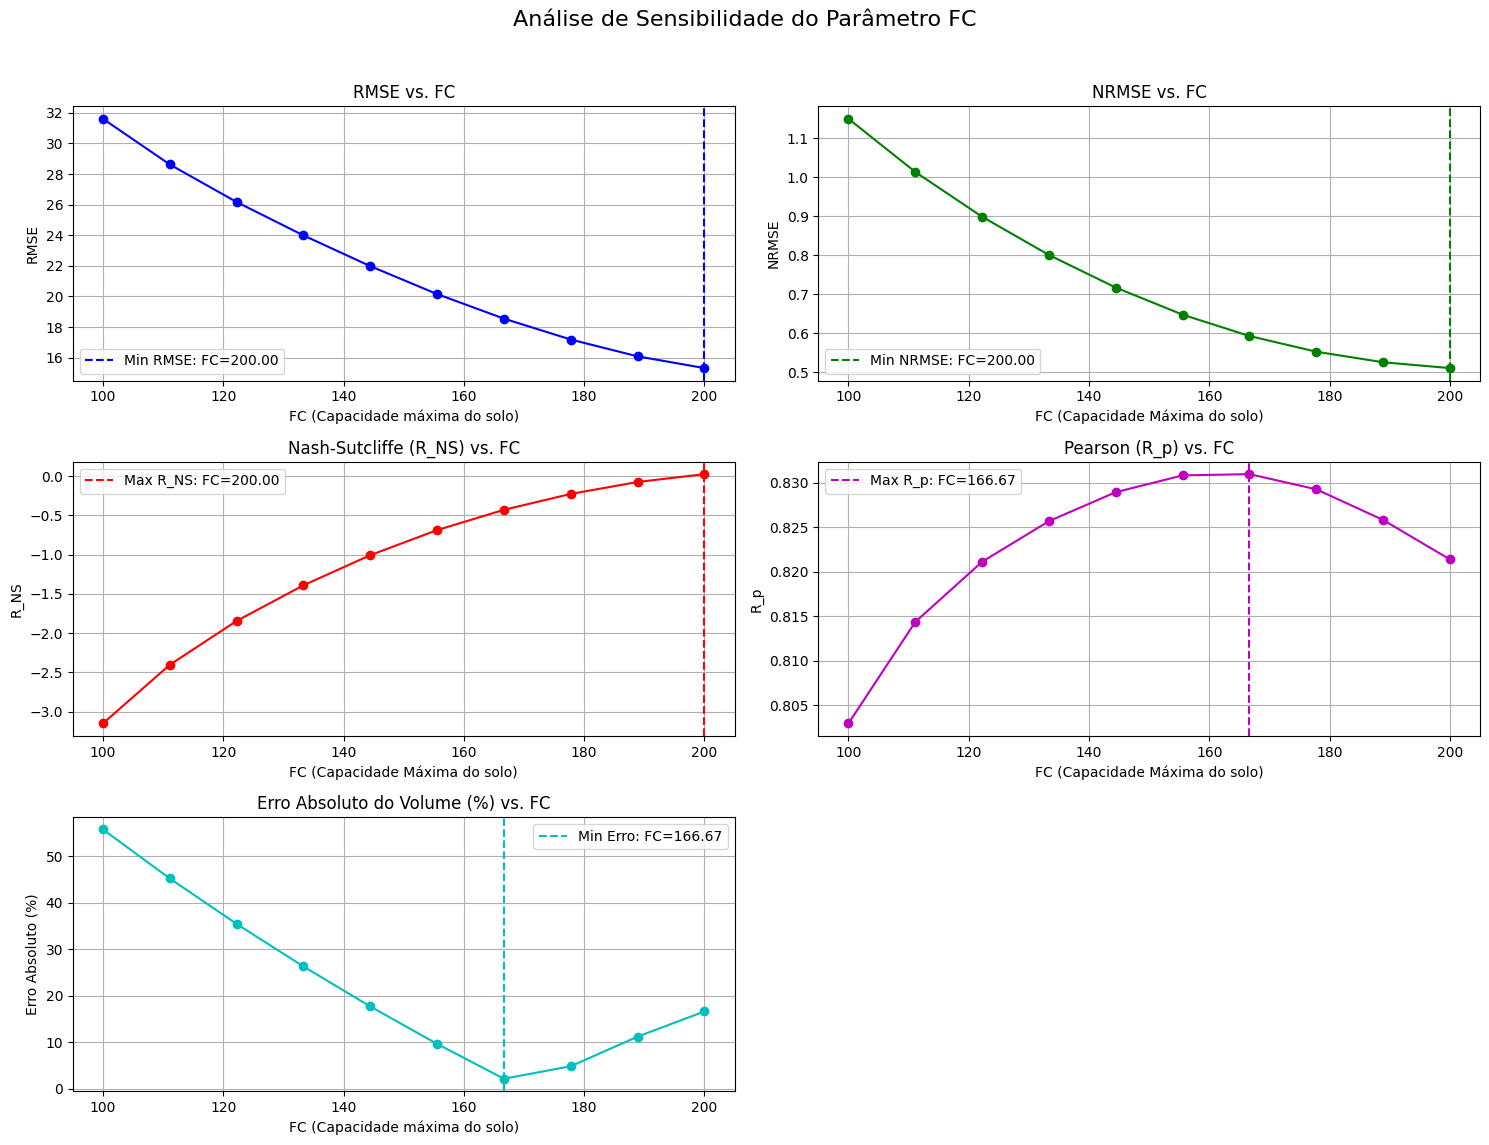

In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do FC ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro FC', fontsize=16)

# 1. RMSE vs DD
axs[0, 0].plot(FCs, RMSEs_FC, 'o-b')
axs[0, 0].set_title('RMSE vs. FC')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('FC (Capacidade máxima do solo)')
axs[0, 0].axvline(x=FCs[np.argmin(RMSEs_FC)], color='b', linestyle='--', label=f'Min RMSE: FC={FCs[np.argmin(RMSEs_FC)]:.2f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs FC
axs[0, 1].plot(FCs, NRMSEs_FC, 'o-g')
axs[0, 1].set_title('NRMSE vs. FC')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('FC (Capacidade Máxima do solo)')
axs[0, 1].axvline(x=FCs[np.argmin(NRMSEs_FC)], color='g', linestyle='--', label=f'Min NRMSE: FC={FCs[np.argmin(NRMSEs_FC)]:.2f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs FC
axs[1, 0].plot(FCs, Rns_FC, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. FC')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('FC (Capacidade Máxima do solo)')
axs[1, 0].axvline(x=FCs[np.argmax(Rns_FC)], color='r', linestyle='--', label=f'Max R_NS: FC={FCs[np.argmax(Rns_FC)]:.2f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs FC
axs[1, 1].plot(FCs, Rp_FC, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. FC')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('FC (Capacidade Máxima do solo)')
axs[1, 1].axvline(x=FCs[np.argmax(Rp_FC)], color='m', linestyle='--', label=f'Max R_p: FC={FCs[np.argmax(Rp_FC)]:.2f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs FC
axs[2, 0].plot(FCs, erroabs_FC, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. FC')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('FC (Capacidade máxima do solo)')
axs[2, 0].axvline(x=FCs[np.argmin(erroabs_FC)], color='c', linestyle='--', label=f'Min Erro: FC={FCs[np.argmin(erroabs_FC)]:.2f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

#O melhor valor testado é de 200.00, mas parece que o valor ideal vai ser acima disso

-0.32581266246107654
-0.09694541150141882


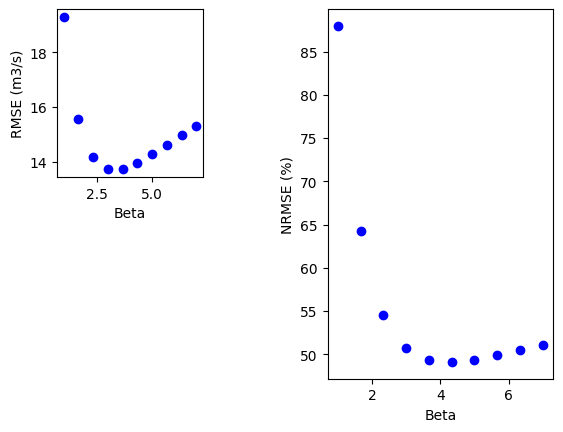

In [ ]:
################## Beta

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_Beta = np.zeros(Betas.shape)
NRMSEs_Beta = np.zeros(Betas.shape)
Rns_Beta = np.zeros(Betas.shape)
Rp_Beta = np.zeros(Betas.shape)
erroabs_Beta = np.zeros(Betas.shape)

# Loop nos Beta
for idd in np.arange(len(Betas)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Betas[idd])*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_Beta[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_Beta[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_Beta[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_Beta[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_Beta[idd] = (numerador_ea / denominador_ea) * 100


# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.subplot(2,3,1)
plt.plot(Betas,RMSEs_Beta,'bo')
plt.xlabel('Beta')
plt.ylabel('RMSE (m3/s)')

plt.subplot(1,2,2)
plt.plot(Betas,NRMSEs_Beta*100.,'bo')
plt.xlabel('Beta')
plt.ylabel('NRMSE (%)')

sens_Beta, intercept, r_value, p_value, std_err = linregress(Betas, RMSEs_Beta)
sens_Beta_norm, intercept, r_value, p_value, std_err = linregress(np.log(Betas), np.log(RMSEs_Beta))

print(sens_Beta)
print(sens_Beta_norm)

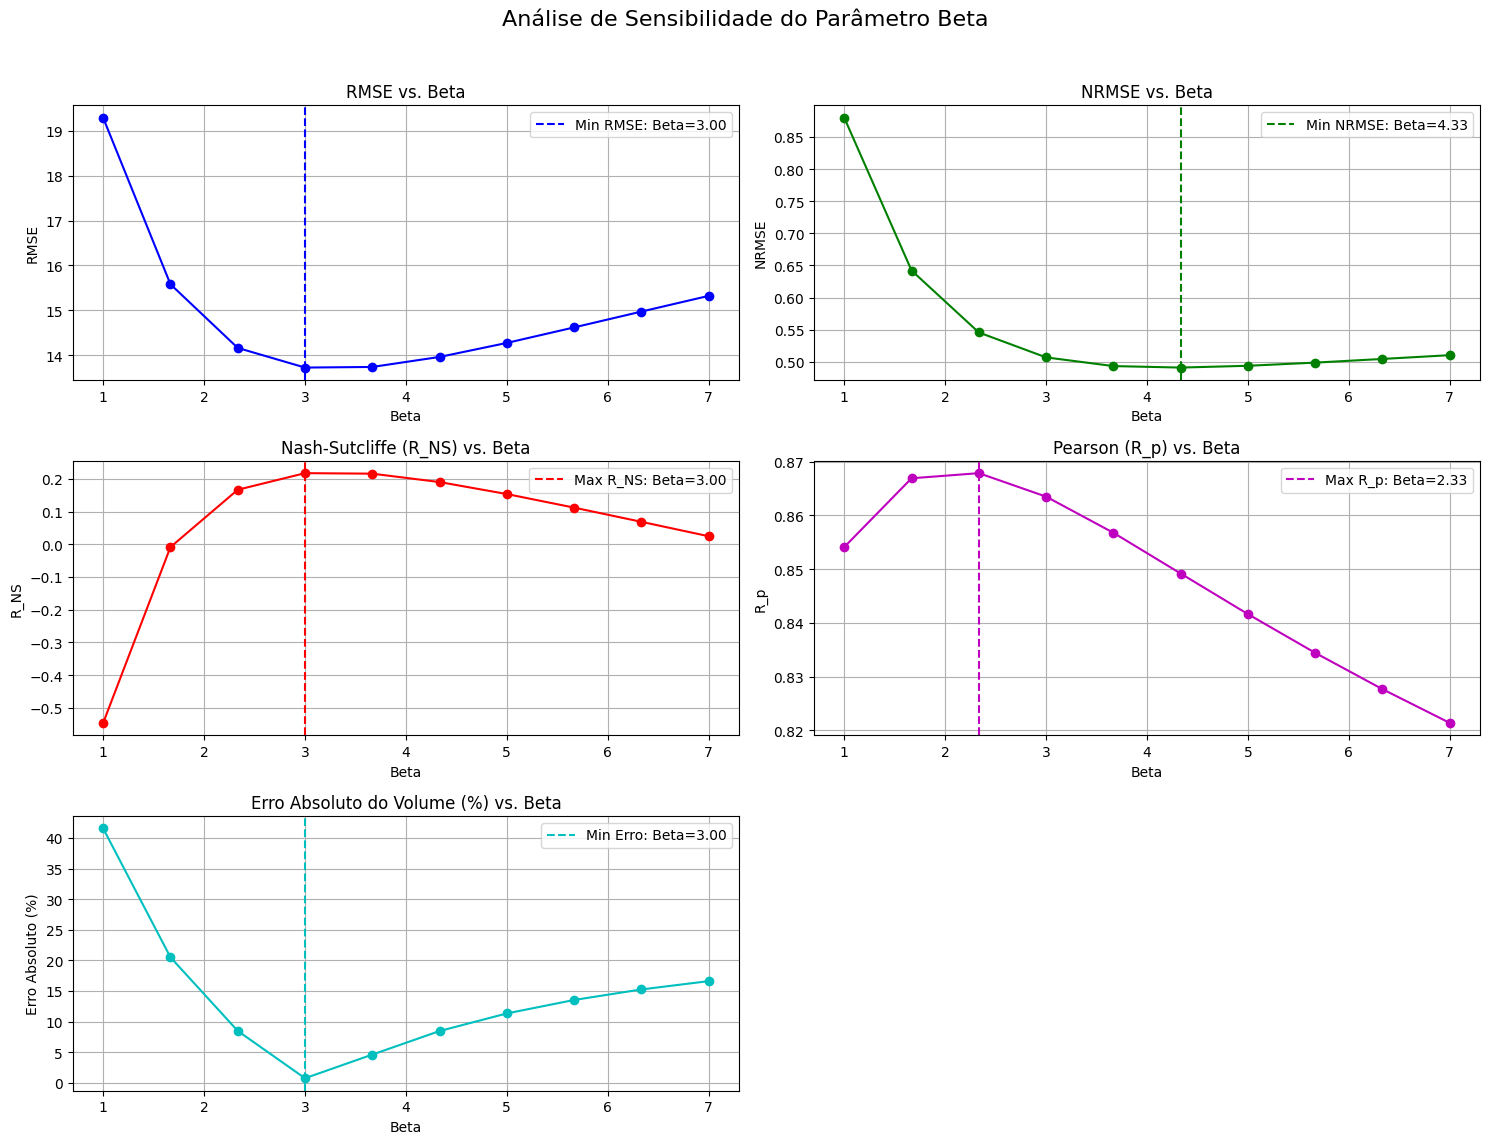

-0.32581266246107654
-0.09694541150141882


In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do Beta ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro Beta', fontsize=16)

# 1. RMSE vs Beta
axs[0, 0].plot(Betas, RMSEs_Beta, 'o-b')
axs[0, 0].set_title('RMSE vs. Beta')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('Beta')
axs[0, 0].axvline(x=Betas[np.argmin(RMSEs_Beta)], color='b', linestyle='--', label=f'Min RMSE: Beta={Betas[np.argmin(RMSEs_Beta)]:.2f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs Beta
axs[0, 1].plot(Betas, NRMSEs_Beta, 'o-g')
axs[0, 1].set_title('NRMSE vs. Beta')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('Beta')
axs[0, 1].axvline(x=Betas[np.argmin(NRMSEs_Beta)], color='g', linestyle='--', label=f'Min NRMSE: Beta={Betas[np.argmin(NRMSEs_Beta)]:.2f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs Beta
axs[1, 0].plot(Betas, Rns_Beta, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. Beta')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('Beta')
axs[1, 0].axvline(x=Betas[np.argmax(Rns_Beta)], color='r', linestyle='--', label=f'Max R_NS: Beta={Betas[np.argmax(Rns_Beta)]:.2f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs Beta
axs[1, 1].plot(Betas, Rp_Beta, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. Beta')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('Beta')
axs[1, 1].axvline(x=Betas[np.argmax(Rp_Beta)], color='m', linestyle='--', label=f'Max R_p: Beta={Betas[np.argmax(Rp_Beta)]:.2f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs Beta
axs[2, 0].plot(Betas, erroabs_Beta, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. Beta')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('Beta')
axs[2, 0].axvline(x=Betas[np.argmin(erroabs_Beta)], color='c', linestyle='--', label=f'Min Erro: Beta={Betas[np.argmin(erroabs_Beta)]:.2f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

# Você pode remover as linhas sens_Beta, pois os gráficos são mais visuais
# Mas se quiser mantê-las, tudo bem.
sens_Beta, intercept, r_value, p_value, std_err = linregress(Betas, RMSEs_Beta)
sens_Beta_norm, intercept, r_value, p_value, std_err = linregress(np.log(Betas), np.log(RMSEs_Beta))

print(sens_Beta)
print(sens_Beta_norm)

#A questão aqui é qual é melhor, Beta = 4.33 ou 5.67. 4.33 traz o melhor formato de hidrograma, e 5.67 chega num volume total mais próximo do observado

4.734112122740598
0.009520186110274793


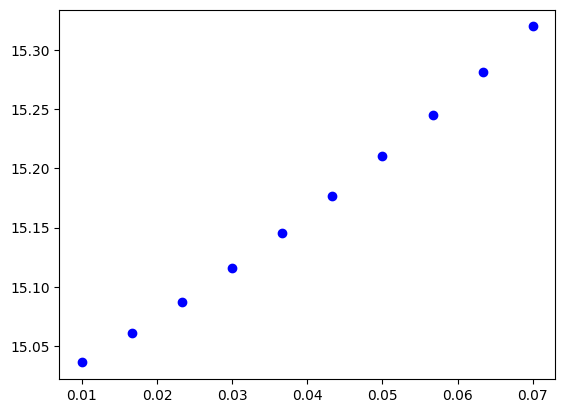

In [ ]:
################## C

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_C = np.zeros(Cs.shape)
NRMSEs_C = np.zeros(Cs.shape)
Rns_C = np.zeros(Cs.shape)
Rp_C = np.zeros(Cs.shape)
erroabs_C = np.zeros(Cs.shape)

# Loop nos C
for idd in np.arange(len(Cs)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + Cs[idd]*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_C[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_C[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_C[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_C[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_C[idd] = (numerador_ea / denominador_ea) * 100

# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(Cs,RMSEs_C,'bo')
sens_C, intercept, r_value, p_value, std_err = linregress(Cs, RMSEs_C)
sens_norm_C, intercept, r_value, p_value, std_err = linregress(np.log(Cs), np.log(RMSEs_C))

print(sens_C)
print(sens_norm_C)
##depois: v = [sens_parametro, sens_parametro2, ...]
##vetor de 1 a 10
#outro notebook: otimização

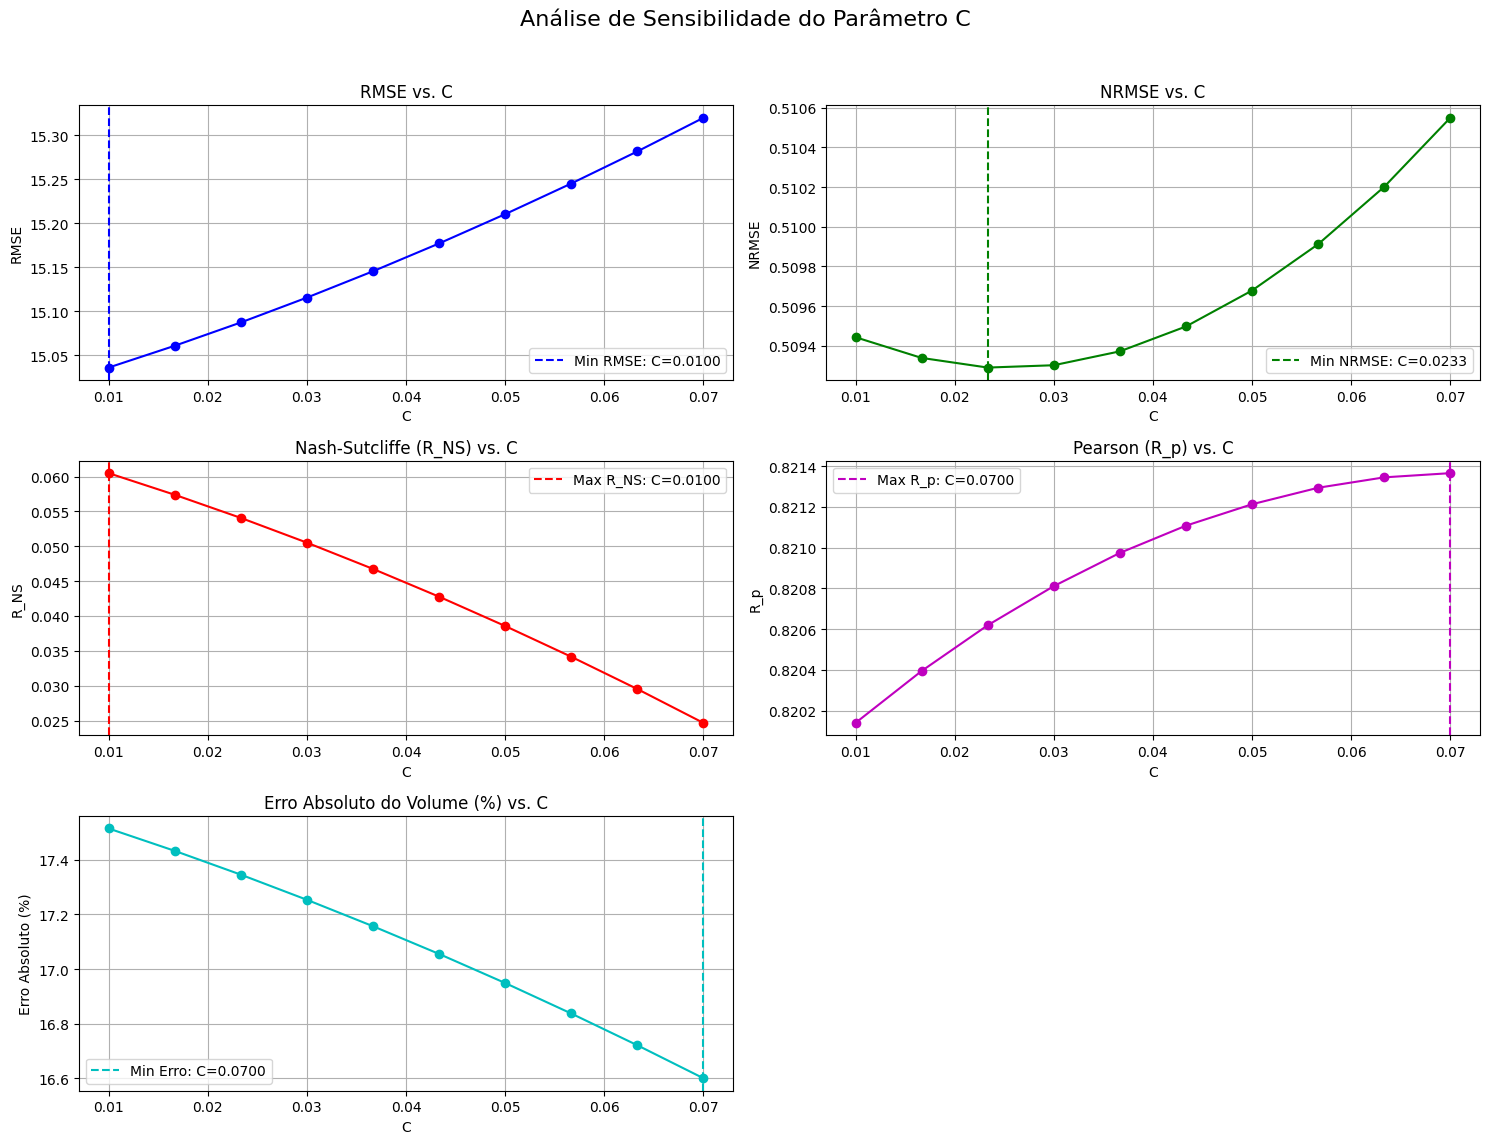

4.734112122740598
0.009520186110274793


In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do C ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro C', fontsize=16)

# 1. RMSE vs C
axs[0, 0].plot(Cs, RMSEs_C, 'o-b')
axs[0, 0].set_title('RMSE vs. C')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('C')
axs[0, 0].axvline(x=Cs[np.argmin(RMSEs_C)], color='b', linestyle='--', label=f'Min RMSE: C={Cs[np.argmin(RMSEs_C)]:.4f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs C
axs[0, 1].plot(Cs, NRMSEs_C, 'o-g')
axs[0, 1].set_title('NRMSE vs. C')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('C')
axs[0, 1].axvline(x=Cs[np.argmin(NRMSEs_C)], color='g', linestyle='--', label=f'Min NRMSE: C={Cs[np.argmin(NRMSEs_C)]:.4f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs C
axs[1, 0].plot(Cs, Rns_C, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. C')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('C')
axs[1, 0].axvline(x=Cs[np.argmax(Rns_C)], color='r', linestyle='--', label=f'Max R_NS: C={Cs[np.argmax(Rns_C)]:.4f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs C
axs[1, 1].plot(Cs, Rp_C, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. C')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('C')
axs[1, 1].axvline(x=Cs[np.argmax(Rp_C)], color='m', linestyle='--', label=f'Max R_p: C={Cs[np.argmax(Rp_C)]:.4f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs C
axs[2, 0].plot(Cs, erroabs_C, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. C')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('C')
axs[2, 0].axvline(x=Cs[np.argmin(erroabs_C)], color='c', linestyle='--', label=f'Min Erro: C={Cs[np.argmin(erroabs_C)]:.4f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

# Calcula a sensibilidade (regressão linear)
sens_C, intercept, r_value, p_value, std_err = linregress(Cs, RMSEs_C)
sens_norm_C, intercept, r_value, p_value, std_err = linregress(np.log(Cs), np.log(RMSEs_C))
print(sens_C)
print(sens_norm_C)

#Melhor usar C = 0.01

14.253663856514137
0.10733652346083737


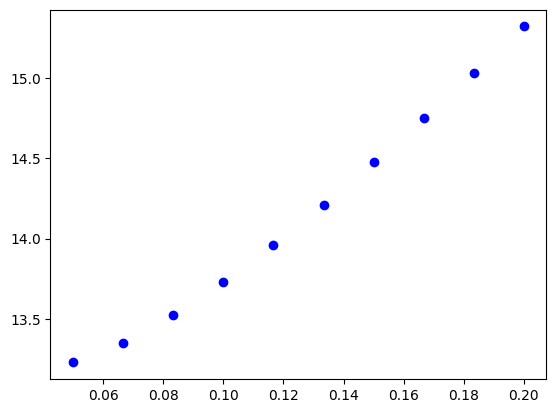

In [ ]:
################## K0

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_K_0 = np.zeros(K_0s.shape)
NRMSEs_K_0 = np.zeros(K_0s.shape)
Rns_K_0 = np.zeros(K_0s.shape)
Rp_K_0 = np.zeros(K_0s.shape)
erroabs_K_0 = np.zeros(K_0s.shape)

# Loop nos K_0
for idd in np.arange(len(K_0s)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0s[idd]*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0s[idd] - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_K_0[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_K_0[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_K_0[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_K_0[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_K_0[idd] = (numerador_ea / denominador_ea) * 100

# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(K_0s,RMSEs_K_0,'bo')
sens_K_0, intercept, r_value, p_value, std_err = linregress(K_0s, RMSEs_K_0)
sens_norm_K_0, intercept, r_value, p_value, std_err = linregress(np.log(K_0s), np.log(RMSEs_K_0))

print(sens_K_0)
print(sens_norm_K_0)

array([[<Axes: title={'center': 'RMSE vs. K_0'}, xlabel='K_0', ylabel='RMSE'>,
        <Axes: title={'center': 'NRMSE vs. K_0'}, xlabel='K_0', ylabel='NRMSE'>],
       [<Axes: title={'center': 'Nash-Sutcliffe (R_NS) vs. K_0'}, xlabel='K_0', ylabel='R_NS'>,
        <Axes: title={'center': 'Pearson (R_p) vs. K_0'}, xlabel='K_0', ylabel='R_p'>],
       [<Axes: title={'center': 'Erro Absoluto do Volume (%) vs. K_0'}, xlabel='K_0', ylabel='Erro Absoluto (%)'>,
        <Axes: >]], dtype=object)

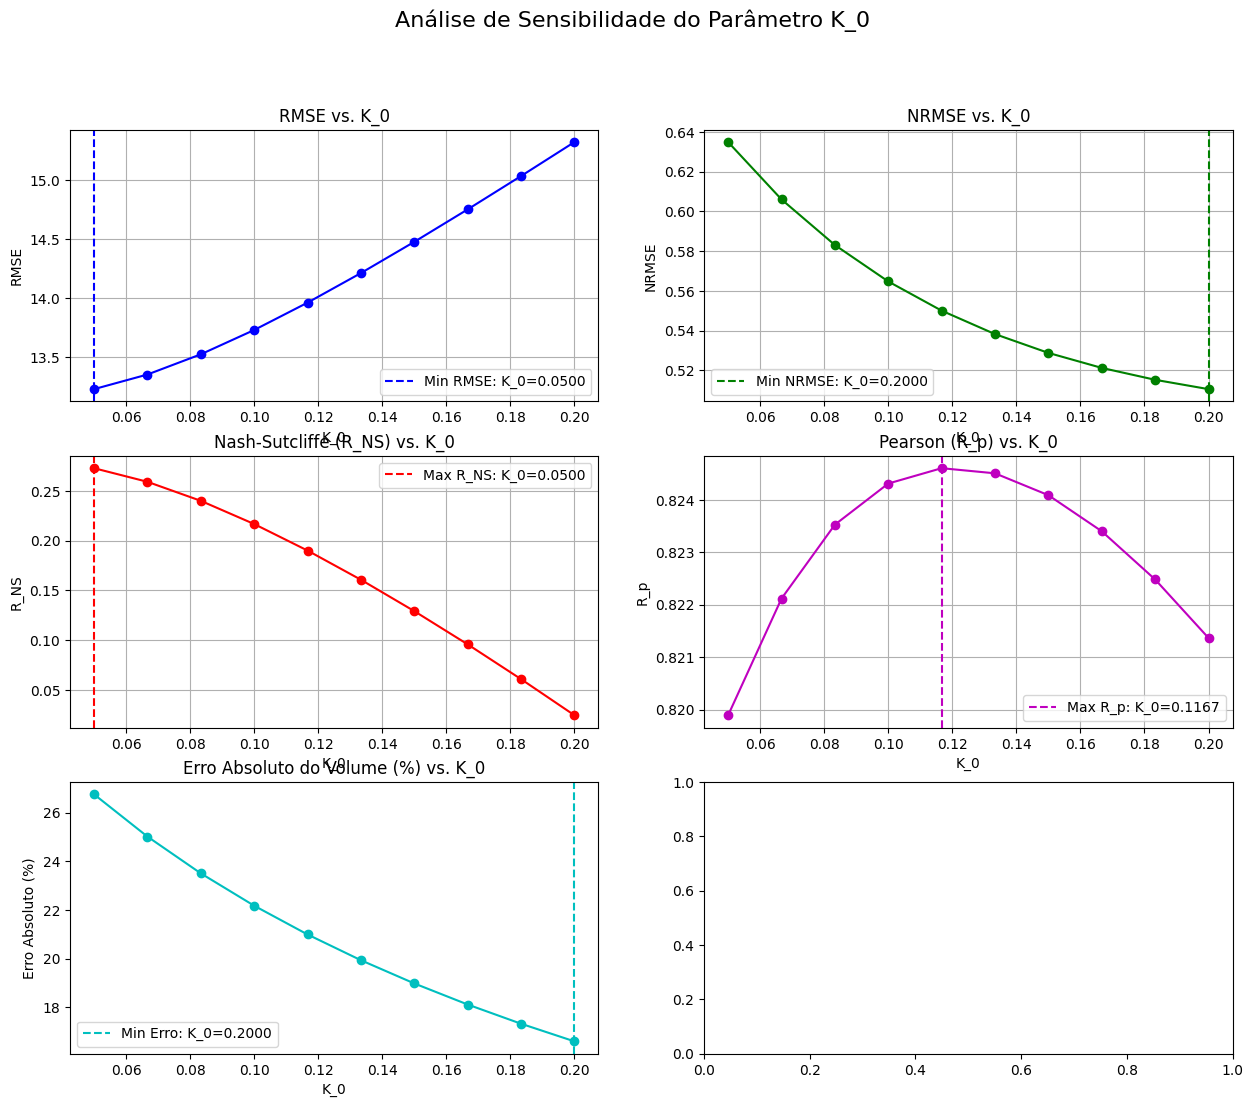

In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do K_0 ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro K_0', fontsize=16)

# 1. RMSE vs K_0
axs[0, 0].plot(K_0s, RMSEs_K_0, 'o-b')
axs[0, 0].set_title('RMSE vs. K_0')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('K_0')
axs[0, 0].axvline(x=K_0s[np.argmin(RMSEs_K_0)], color='b', linestyle='--', label=f'Min RMSE: K_0={K_0s[np.argmin(RMSEs_K_0)]:.4f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs K_0
axs[0, 1].plot(K_0s, NRMSEs_K_0, 'o-g')
axs[0, 1].set_title('NRMSE vs. K_0')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('K_0')
axs[0, 1].axvline(x=K_0s[np.argmin(NRMSEs_K_0)], color='g', linestyle='--', label=f'Min NRMSE: K_0={K_0s[np.argmin(NRMSEs_K_0)]:.4f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs K_0
axs[1, 0].plot(K_0s, Rns_K_0, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. K_0')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('K_0')
axs[1, 0].axvline(x=K_0s[np.argmax(Rns_K_0)], color='r', linestyle='--', label=f'Max R_NS: K_0={K_0s[np.argmax(Rns_K_0)]:.4f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs K_0
axs[1, 1].plot(K_0s, Rp_K_0, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. K_0')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('K_0')
axs[1, 1].axvline(x=K_0s[np.argmax(Rp_K_0)], color='m', linestyle='--', label=f'Max R_p: K_0={K_0s[np.argmax(Rp_K_0)]:.4f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs K_0
axs[2, 0].plot(K_0s, erroabs_K_0, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. K_0')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('K_0')
axs[2, 0].axvline(x=K_0s[np.argmin(erroabs_K_0)], color='c', linestyle='--', label=f'Min Erro: K_0={K_0s[np.argmin(erroabs_K_0)]:.4f}')
axs[2, 0].legend()
axs

#usar K_0 = 0.0667

10.881213542394118
0.02826669997519436


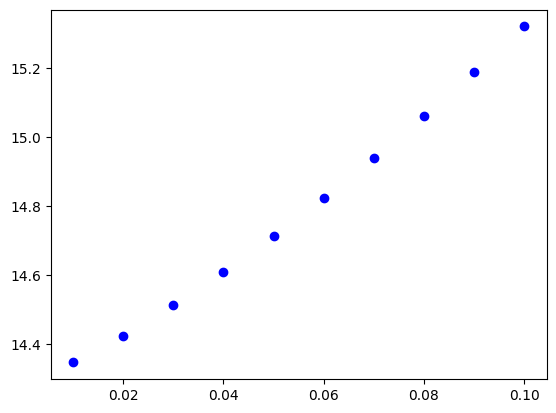

In [ ]:
################## K1

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_K_1 = np.zeros(K_1s.shape)
NRMSEs_K_1 = np.zeros(K_1s.shape)
Rns_K_1 = np.zeros(K_1s.shape)
Rp_K_1 = np.zeros(K_1s.shape)
erroabs_K_1 = np.zeros(K_1s.shape)

# Loop nos K_1
for idd in np.arange(len(K_1s)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1s[idd]*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1s[idd]) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

    Q = Q0s + Q1s + Q2s

    RMSEs_K_1[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_K_1[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_K_1[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_K_1[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_K_1[idd] = (numerador_ea / denominador_ea) * 100

# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(K_1s,RMSEs_K_1,'bo')
sens_K_1, intercept, r_value, p_value, std_err = linregress(K_1s, RMSEs_K_1)
sens_K_1_norm, intercept, r_value, p_value, std_err = linregress(np.log(K_1s), np.log(RMSEs_K_1))

print(sens_K_1)
print(sens_K_1_norm)

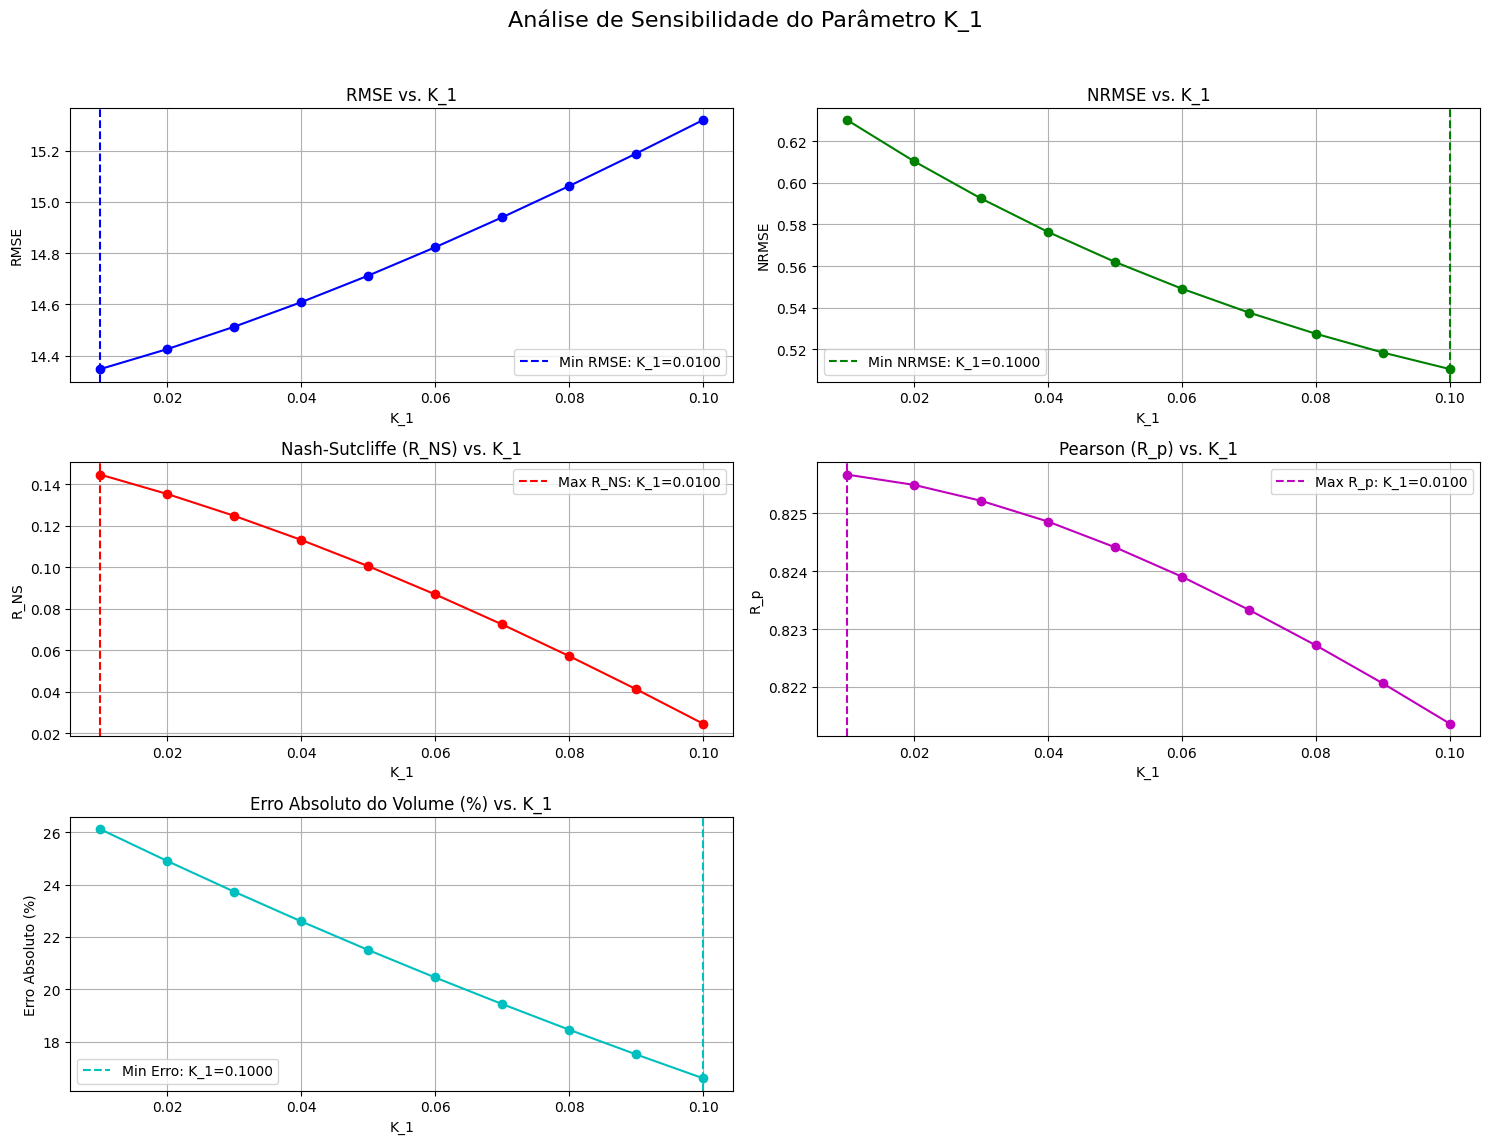

10.881213542394118
0.02826669997519436


In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do K_1 ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro K_1', fontsize=16)

# 1. RMSE vs K_1
axs[0, 0].plot(K_1s, RMSEs_K_1, 'o-b')
axs[0, 0].set_title('RMSE vs. K_1')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('K_1')
axs[0, 0].axvline(x=K_1s[np.argmin(RMSEs_K_1)], color='b', linestyle='--', label=f'Min RMSE: K_1={K_1s[np.argmin(RMSEs_K_1)]:.4f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs K_1
axs[0, 1].plot(K_1s, NRMSEs_K_1, 'o-g')
axs[0, 1].set_title('NRMSE vs. K_1')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('K_1')
axs[0, 1].axvline(x=K_1s[np.argmin(NRMSEs_K_1)], color='g', linestyle='--', label=f'Min NRMSE: K_1={K_1s[np.argmin(NRMSEs_K_1)]:.4f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs K_1
axs[1, 0].plot(K_1s, Rns_K_1, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. K_1')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('K_1')
# A linha abaixo foi a que deu erro. Garanta que ela seja copiada inteiramente.
axs[1, 0].axvline(x=K_1s[np.argmax(Rns_K_1)], color='r', linestyle='--', label=f'Max R_NS: K_1={K_1s[np.argmax(Rns_K_1)]:.4f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs K_1
axs[1, 1].plot(K_1s, Rp_K_1, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. K_1')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('K_1')
axs[1, 1].axvline(x=K_1s[np.argmax(Rp_K_1)], color='m', linestyle='--', label=f'Max R_p: K_1={K_1s[np.argmax(Rp_K_1)]:.4f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs K_1
axs[2, 0].plot(K_1s, erroabs_K_1, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. K_1')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('K_1')
axs[2, 0].axvline(x=K_1s[np.argmin(erroabs_K_1)], color='c', linestyle='--', label=f'Min Erro: K_1={K_1s[np.argmin(erroabs_K_1)]:.4f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

# Calcula a sensibilidade (regressão linear)
sens_K_1, intercept, r_value, p_value, std_err = linregress(K_1s, RMSEs_K_1)
sens_K_1_norm, intercept, r_value, p_value, std_err = linregress(np.log(K_1s), np.log(RMSEs_K_1))

print(sens_K_1)
print(sens_K_1_norm)

#usar K_1 = 0.0100

142.46147303553508
0.28703954654034564


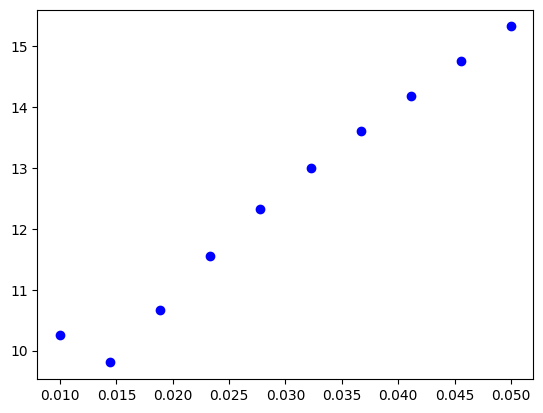

In [ ]:
################## K2

# Vamos variar um parâmetro e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção do parâmetro a ser alterado

RMSEs_K_2 = np.zeros(K_2s.shape)
NRMSEs_K_2 = np.zeros(K_2s.shape)
Rns_K_2 = np.zeros(K_2s.shape)
Rp_K_2 = np.zeros(K_2s.shape)
erroabs_K_2 = np.zeros(K_2s.shape)


# Loop nos K_2
for idd in np.arange(len(K_1s)):
    # Loop nos dados diários
    for idia in np.arange(1,len(P)):
        # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
        if T[idia]<=Tt:
            # Não haverá derretimento, portanto Sm = 0
            Sm = 0.

            # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
            neve[idia] = neve[idia-1] + P[idia]

            # Nesse caso não haverá chuva efetiva também
            Peff = 0.

            # Não haverá contribuição de P para a umidade do solo
            P_solo = 0.

        else:
            # Nesse caso haverá derretimento pela equação do modelo,
            # mas o derretimento não pode superar o nível do reservatório
            # de neve
            Sm = min(neve[idia-1],DD*(T[idia]-Tt))

            # Como derreteu, iremos reduzir o reservatório de neve
            neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

            # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
            Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

            # A chuva P poderá contribuir para a umidade do solo caso P>Peff
            P_solo = P[idia]

        # Agora vamos calcular a ET real
        # Primeiro ajusta a ET potencial em função da T do dia
        PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        # Agora sim calcula a ET real
        if umidade_solo[idia-1]<PWP:
            Ea = PEa*(umidade_solo[idia-1]/PWP)
        else:
            Ea = PEa

        # Ajusta a umidade do solo
        umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
        # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
        # A divisão por (24*3600) converte de dia-1 para s-1
        if S_1s[idia-1]>L:
            Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = K_1s[idd]*S_1s[idia-1]*A*1000./(24.*3600.)
        #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

        Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Ajusta o nível do reservatório 1
        S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
        # Ajusta o nível do reservatório 2
        S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2s[idd]))

    Q = Q0s + Q1s + Q2s

    RMSEs_K_2[idd] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    NRMSEs_K_2[idd] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))

    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_K_2[idd] = 1 - numerador_ns/denominador_ns

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_K_2[idd] = matriz_corr[0, 1]

    numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
    denominador_ea = np.sum(Qobs)
    erroabs_K_2[idd] = (numerador_ea / denominador_ea) * 100


# A sensibilidade do modelo pode ser estimada por dRMSE/dDD
plt.plot(K_2s,RMSEs_K_2,'bo')
sens_K_2, intercept, r_value, p_value, std_err = linregress(K_2s, RMSEs_K_2)
sens_K_2_norm, intercept, r_value, p_value, std_err = linregress(np.log(K_2s), np.log(RMSEs_K_2))

print(sens_K_2)
print(sens_K_2_norm)

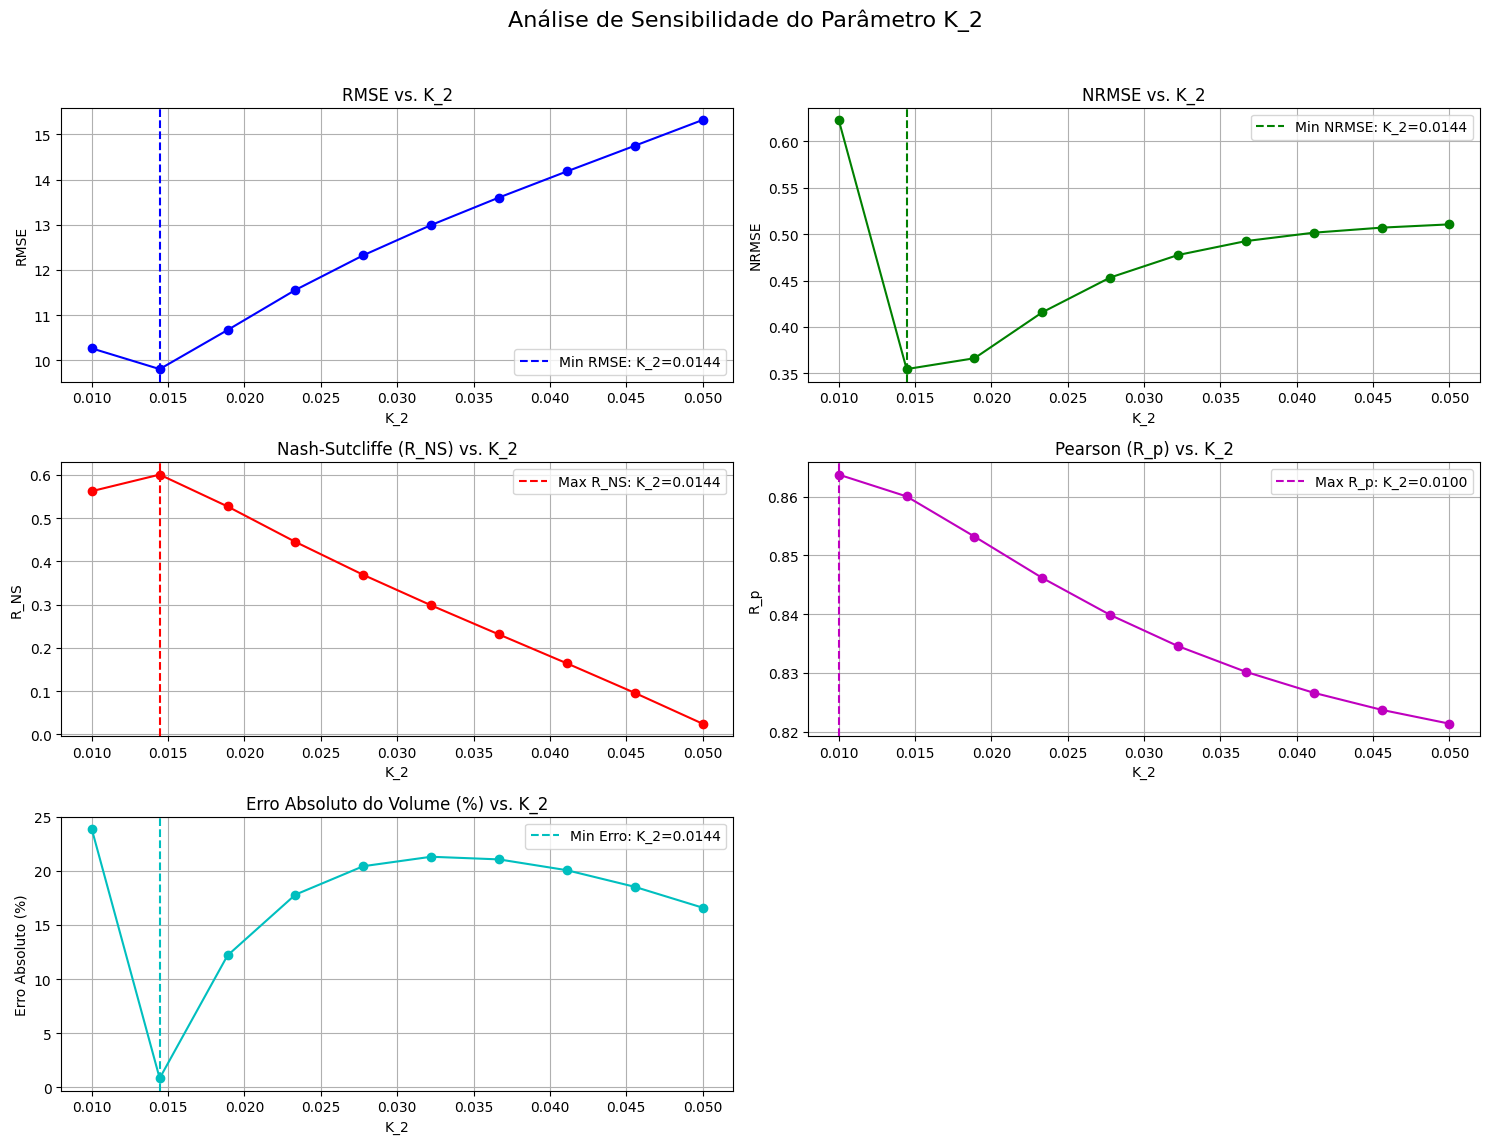

142.46147303553508
0.28703954654034564


In [ ]:
# --- Bloco de Código para Plotar a Análise de Sensibilidade do K_2 ---

fig, axs = plt.subplots(3, 2, figsize=(15, 12)) # Cria uma grade de 3x2 plots
fig.suptitle('Análise de Sensibilidade do Parâmetro K_2', fontsize=16)

# 1. RMSE vs K_2
axs[0, 0].plot(K_2s, RMSEs_K_2, 'o-b')
axs[0, 0].set_title('RMSE vs. K_2')
axs[0, 0].set_ylabel('RMSE')
axs[0, 0].set_xlabel('K_2')
axs[0, 0].axvline(x=K_2s[np.argmin(RMSEs_K_2)], color='b', linestyle='--', label=f'Min RMSE: K_2={K_2s[np.argmin(RMSEs_K_2)]:.4f}')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. NRMSE vs K_2
axs[0, 1].plot(K_2s, NRMSEs_K_2, 'o-g')
axs[0, 1].set_title('NRMSE vs. K_2')
axs[0, 1].set_ylabel('NRMSE')
axs[0, 1].set_xlabel('K_2')
axs[0, 1].axvline(x=K_2s[np.argmin(NRMSEs_K_2)], color='g', linestyle='--', label=f'Min NRMSE: K_2={K_2s[np.argmin(NRMSEs_K_2)]:.4f}')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Nash-Sutcliffe (R_NS) vs K_2
axs[1, 0].plot(K_2s, Rns_K_2, 'o-r')
axs[1, 0].set_title('Nash-Sutcliffe (R_NS) vs. K_2')
axs[1, 0].set_ylabel('R_NS')
axs[1, 0].set_xlabel('K_2')
axs[1, 0].axvline(x=K_2s[np.argmax(Rns_K_2)], color='r', linestyle='--', label=f'Max R_NS: K_2={K_2s[np.argmax(Rns_K_2)]:.4f}')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Pearson (R_p) vs K_2
axs[1, 1].plot(K_2s, Rp_K_2, 'o-m')
axs[1, 1].set_title('Pearson (R_p) vs. K_2')
axs[1, 1].set_ylabel('R_p')
axs[1, 1].set_xlabel('K_2')
axs[1, 1].axvline(x=K_2s[np.argmax(Rp_K_2)], color='m', linestyle='--', label=f'Max R_p: K_2={K_2s[np.argmax(Rp_K_2)]:.4f}')
axs[1, 1].legend()
axs[1, 1].grid(True)

# 5. Erro Absoluto (%) vs K_2
axs[2, 0].plot(K_2s, erroabs_K_2, 'o-c')
axs[2, 0].set_title('Erro Absoluto do Volume (%) vs. K_2')
axs[2, 0].set_ylabel('Erro Absoluto (%)')
axs[2, 0].set_xlabel('K_2')
axs[2, 0].axvline(x=K_2s[np.argmin(erroabs_K_2)], color='c', linestyle='--', label=f'Min Erro: K_2={K_2s[np.argmin(erroabs_K_2)]:.4f}')
axs[2, 0].legend()
axs[2, 0].grid(True)

# Esconder o último subplot vazio (posição 2,1)
axs[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Ajusta para o supertítulo
plt.show()

# Calcula a sensibilidade (regressão linear)
sens_K_2, intercept, r_value, p_value, std_err = linregress(K_2s, RMSEs_K_2)
sens_K_2_norm, intercept, r_value, p_value, std_err = linregress(np.log(K_2s), np.log(RMSEs_K_2))

print(sens_K_2)
print(sens_K_2_norm)

In [ ]:
# --- DEFINIÇÃO DOS PARÂMETROS OTIMIZADOS ---
# Valores ideais encontrados na análise de sensibilidade
# priorizando R_NS e RMSE.

# Parâmetros otimizados:
DD = 3.00       # Melhor R_NS e RMSE
FC = 200.00     # Consenso de todas as métricas (no limite do intervalo)
Beta = 4.33     # Melhor R_NS e RMSE
C = 0.0100      # Melhor R_NS e RMSE
K_0 = 0.0667    # Melhor R_NS e RMSE
K_1 = 0.0100    # Melhor R_NS e RMSE
K_2 = 0.0189    # Melhor R_NS e RMSE

# Parâmetros que ainda não analisamos (mantendo o valor padrão 'final'):
L = Ls[n_int-1]          # Valor padrão: 5.0
K_p = K_ps[n_int-1]      # Valor padrão: 0.05
PWP = PWPs[n_int-1]      # Valor padrão: 180.0


print("--- Parâmetros Otimizados Selecionados ---")
print(f"DD = {DD}")
print(f"FC = {FC}")
print(f"Beta = {Beta}")
print(f"C = {C}")
print(f"K_0 = {K_0}")
print(f"K_1 = {K_1}")
print(f"K_2 = {K_2}")
print("------------------------------------------")
print(f"L = {L} (padrão)")
print(f"K_p = {K_p} (padrão)")
print(f"PWP = {PWP} (padrão)")

--- Parâmetros Otimizados Selecionados ---
DD = 3.0
FC = 200.0
Beta = 4.33
C = 0.01
K_0 = 0.0667
K_1 = 0.01
K_2 = 0.0189
------------------------------------------
L = 5.0 (padrão)
K_p = 0.05 (padrão)
PWP = 180.0 (padrão)


Text(0.5, 1.0, 'RMSE vs Beta e C')

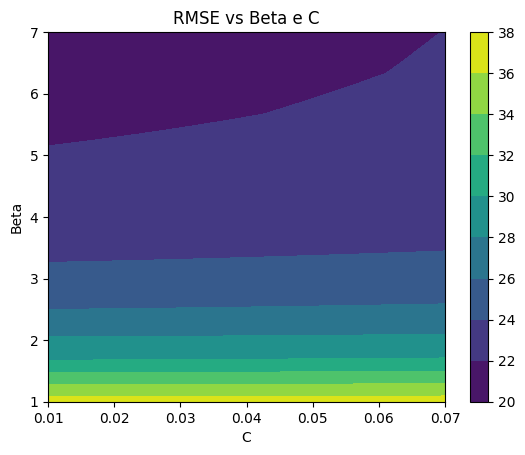

In [ ]:
# Teste variando tanto Beta quanto C
################## Beta e C

# Vamos variar dois parâmetros e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção dos parâmetros a serem alterados

RMSEs_BetaC = np.zeros([len(Betas), len(Cs)])
NRMSEs_BetaC = np.zeros([len(Betas), len(Cs)])

# Loop nos Betas
for ibeta in np.arange(len(Betas)):
    # Loop nos C
    for ic in np.arange(len(Betas)):
        # Loop nos dados diários
        for idia in np.arange(1,len(P)):
            # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
            if T[idia]<=Tt:
                # Não haverá derretimento, portanto Sm = 0
                Sm = 0.

                # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
                neve[idia] = neve[idia-1] + P[idia]

                # Nesse caso não haverá chuva efetiva também
                Peff = 0.

                # Não haverá contribuição de P para a umidade do solo
                P_solo = 0.

            else:
                # Nesse caso haverá derretimento pela equação do modelo,
                # mas o derretimento não pode superar o nível do reservatório
                # de neve
                Sm = min(neve[idia-1],DD*(T[idia]-Tt))

                # Como derreteu, iremos reduzir o reservatório de neve
                neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

                # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
                Peff = ((umidade_solo[idia-1]/FC)**Betas[ibeta])*(P[idia] + Sm)

                # A chuva P poderá contribuir para a umidade do solo caso P>Peff
                P_solo = P[idia]

            # Agora vamos calcular a ET real
            # Primeiro ajusta a ET potencial em função da T do dia
            PEa = (1 + Cs[ic]*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
            # Agora sim calcula a ET real
            if umidade_solo[idia-1]<PWP:
                Ea = PEa*(umidade_solo[idia-1]/PWP)
            else:
                Ea = PEa

            # Ajusta a umidade do solo
            umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

            # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
            # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
            # A divisão por (24*3600) converte de dia-1 para s-1
            if S_1s[idia-1]>L:
                Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
            else:
                Q0s[idia] = 0.

            Q1s[idia] = K_1s[idd]*S_1s[idia-1]*A*1000./(24.*3600.)
            #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

            Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

            # Ajusta o nível do reservatório 1
            S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
            # Ajusta o nível do reservatório 2
            S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

        Q = Q0s + Q1s + Q2s

        RMSEs_BetaC[ibeta,ic] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
        NRMSEs_BetaC[ibeta,ic] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))


X, Y = np.meshgrid(Cs,Betas)
plt.contourf(X,Y,RMSEs_BetaC)
plt.colorbar()
plt.xlabel('C')
plt.ylabel('Beta')
plt.title('RMSE vs Beta e C')

In [ ]:
# A figura acima sugere que devemos utilizar C = 0.01 e Beta = 4. Então vamos fazer o teste
# Agora vamos começar a programar o modelo em si considerando
# apenas 1 valor dos parâmetros do modelo (célula anterior)
DD = DDs[n_int-1]
FC = FCs[n_int-1]
Beta = 4.
C = 0.01
K_0 = K_0s[n_int-1]
L = Ls[n_int-1]
K_1 = K_1s[n_int-1]
K_2 = K_2s[n_int-1]
K_p = K_ps[n_int-1]
PWP = PWPs[n_int-1]

# Variáveis que irão armazenar a evolução do acumulado de neve e da umidade do solo
neve = np.zeros(P.shape)
umidade_solo = np.zeros(P.shape)
umidade_solo[0] = SM

# Variáveis que irão armazenar as vazões
Q0s = np.zeros(P.shape)
Q1s = np.zeros(P.shape)
Q2s = np.zeros(P.shape)

# Variáveis que irão armazenar os níveis dos reservatórios 1 e 2
S_1s = np.zeros(P.shape)
S_1s[0] = S_1
S_2s = np.zeros(P.shape)
S_2s[0] = S_2

# Loop nos dados diários
for idia in np.arange(1,len(P)):
    # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
    if T[idia]<=Tt:
        # Não haverá derretimento, portanto Sm = 0
        Sm = 0.

        # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
        neve[idia] = neve[idia-1] + P[idia]

        # Nesse caso não haverá chuva efetiva também
        Peff = 0.

        # Não haverá contribuição de P para a umidade do solo
        P_solo = 0.

    else:
        # Nesse caso haverá derretimento pela equação do modelo,
        # mas o derretimento não pode superar o nível do reservatório
        # de neve
        Sm = min(neve[idia-1],DD*(T[idia]-Tt))

        # Como derreteu, iremos reduzir o reservatório de neve
        neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

        # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
        Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

        # A chuva P poderá contribuir para a umidade do solo caso P>Peff
        P_solo = P[idia]

    # Agora vamos calcular a ET real
    # Primeiro ajusta a ET potencial em função da T do dia
    PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
    # Agora sim calcula a ET real
    if umidade_solo[idia-1]<PWP:
        Ea = PEa*(umidade_solo[idia-1]/PWP)
    else:
        Ea = PEa

    # Ajusta a umidade do solo
    umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

    # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
    # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
    # A divisão por (24*3600) converte de dia-1 para s-1
    if S_1s[idia-1]>L:
        Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
    else:
        Q0s[idia] = 0.

    Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
    #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

    Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

    # Ajusta o nível do reservatório 1
    S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
    # Ajusta o nível do reservatório 2
    S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

Q = Q0s + Q1s + Q2s

RMSE_otimizado = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))

print('RMSE antes ', RMSE, ' ', RMSE/np.nanmean(Qobs))
print('RMSE depois ', RMSE_otimizado, ' ', RMSE_otimizado/np.nanmean(Qobs))

RMSE antes  15.31991862623687   0.836546690791705
RMSE depois  13.620538492251447   0.7437517574656218


Text(0.5, 1.0, 'RMSE vs C e K_0')

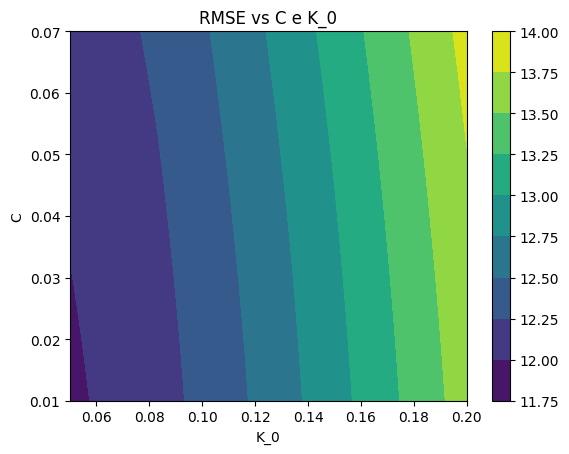

In [ ]:
# Teste variando tanto C quanto K_0
################## C e K_0

# Vamos variar dois parâmetros e manter todos os outros fixos
# Assim vamos poder calcular RMSE para cada opção dos parâmetros a serem alterados

RMSEs_CK_0 = np.zeros([len(Cs), len(K_0s)])
NRMSEs_CK_0 = np.zeros([len(Cs), len(K_0s)])

# Loop nos Cs
for ic in np.arange(len(Cs)):
    # Loop nos K_0s
    for ik0 in np.arange(len(K_0s)):
        # Loop nos dados diários
        for idia in np.arange(1,len(P)):
            # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
            if T[idia]<=Tt:
                # Não haverá derretimento, portanto Sm = 0
                Sm = 0.

                # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
                neve[idia] = neve[idia-1] + P[idia]

                # Nesse caso não haverá chuva efetiva também
                Peff = 0.

                # Não haverá contribuição de P para a umidade do solo
                P_solo = 0.

            else:
                # Nesse caso haverá derretimento pela equação do modelo,
                # mas o derretimento não pode superar o nível do reservatório
                # de neve
                Sm = min(neve[idia-1],DD*(T[idia]-Tt))

                # Como derreteu, iremos reduzir o reservatório de neve
                neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

                # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
                Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

                # A chuva P poderá contribuir para a umidade do solo caso P>Peff
                P_solo = P[idia]

            # Agora vamos calcular a ET real
            # Primeiro ajusta a ET potencial em função da T do dia
            PEa = (1 + Cs[ic]*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
            # Agora sim calcula a ET real
            if umidade_solo[idia-1]<PWP:
                Ea = PEa*(umidade_solo[idia-1]/PWP)
            else:
                Ea = PEa

            # Ajusta a umidade do solo
            umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

            # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
            # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
            # A divisão por (24*3600) converte de dia-1 para s-1
            if S_1s[idia-1]>L:
                Q0s[idia] = K_0s[ik0]*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
            else:
                Q0s[idia] = 0.

            Q1s[idia] = K_1s[idd]*S_1s[idia-1]*A*1000./(24.*3600.)
            #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

            Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

            # Ajusta o nível do reservatório 1
            S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0s[ik0] - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
            # Ajusta o nível do reservatório 2
            S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

        Q = Q0s + Q1s + Q2s

        RMSEs_CK_0[ic,ik0] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
        NRMSEs_CK_0[ic,ik0] = np.sqrt(np.sum((((Q - Qobs)/Qobs)**2)/len(P)))


X, Y = np.meshgrid(K_0s,Cs)
plt.contourf(X,Y,RMSEs_CK_0)
plt.colorbar()
plt.xlabel('K_0')
plt.ylabel('C')
plt.title('RMSE vs C e K_0')

In [ ]:
# A figura acima sugere que devemos utilizar C = 0.01 e Beta = 4. Então vamos fazer o teste
# Agora vamos começar a programar o modelo em si considerando
# apenas 1 valor dos parâmetros do modelo (célula anterior)
DD = DDs[n_int-1]
FC = FCs[n_int-1]
Beta = Betas[n_int-1]
C = Cs[0]
K_0 = K_0s[0]
L = Ls[n_int-1]
K_1 = K_1s[n_int-1]
K_2 = K_2s[n_int-1]
K_p = K_ps[n_int-1]
PWP = PWPs[n_int-1]

# Variáveis que irão armazenar a evolução do acumulado de neve e da umidade do solo
neve = np.zeros(P.shape)
umidade_solo = np.zeros(P.shape)
umidade_solo[0] = SM

# Variáveis que irão armazenar as vazões
Q0s = np.zeros(P.shape)
Q1s = np.zeros(P.shape)
Q2s = np.zeros(P.shape)

# Variáveis que irão armazenar os níveis dos reservatórios 1 e 2
S_1s = np.zeros(P.shape)
S_1s[0] = S_1
S_2s = np.zeros(P.shape)
S_2s[0] = S_2

# Loop nos dados diários
for idia in np.arange(1,len(P)):
    # Primeiro iremos conferir se T < Tt. Se sim, acumula neve. Se não, derrete neve
    if T[idia]<=Tt:
        # Não haverá derretimento, portanto Sm = 0
        Sm = 0.

        # A neve irá acumular, formando um reservatório que poderá ser derretido posteriormente
        neve[idia] = neve[idia-1] + P[idia]

        # Nesse caso não haverá chuva efetiva também
        Peff = 0.

        # Não haverá contribuição de P para a umidade do solo
        P_solo = 0.

    else:
        # Nesse caso haverá derretimento pela equação do modelo,
        # mas o derretimento não pode superar o nível do reservatório
        # de neve
        Sm = min(neve[idia-1],DD*(T[idia]-Tt))

        # Como derreteu, iremos reduzir o reservatório de neve
        neve[idia] = neve[idia-1] - Sm # Tecnicamente teríamos que multiplicar Sm pelo "dt", mas como dt = 1 dia, não mudaria nada

        # Agora vamos calcular a chuva efetiva - com a contribuição do derretimento se houver
        Peff = ((umidade_solo[idia-1]/FC)**Beta)*(P[idia] + Sm)

        # A chuva P poderá contribuir para a umidade do solo caso P>Peff
        P_solo = P[idia]

    # Agora vamos calcular a ET real
    # Primeiro ajusta a ET potencial em função da T do dia
    PEa = (1 + C*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
    # Agora sim calcula a ET real
    if umidade_solo[idia-1]<PWP:
        Ea = PEa*(umidade_solo[idia-1]/PWP)
    else:
        Ea = PEa

    # Ajusta a umidade do solo
    umidade_solo[idia] = max(0,umidade_solo[idia-1] + P_solo - Peff - Ea)

    # Finalmente calcula as vazões superficial, sub-superficial e subterrânea
    # A multiplicação por 1000 converte os níveis dos reservatórios e L em m
    # A divisão por (24*3600) converte de dia-1 para s-1
    if S_1s[idia-1]>L:
        Q0s[idia] = K_0*(S_1s[idia-1] - L)*A*1000./(24.*3600.)
    else:
        Q0s[idia] = 0.

    Q1s[idia] = K_1*S_1s[idia-1]*A*1000./(24.*3600.)
    #Qperc = K_p*S_1s[idia-1]*A*1000./(24.*3600.)

    Q2s[idia] = K_2*S_2s[idia-1]*A*1000./(24.*3600.)

    # Ajusta o nível do reservatório 1
    S_1s[idia] = max(0,S_1s[idia-1] + Peff - (S_1s[idia-1] - L)*K_0 - (S_1s[idia-1]*K_1) - (S_1s[idia-1]*K_p))
    # Ajusta o nível do reservatório 2
    S_2s[idia] = max(0,S_2s[idia-1] + (S_1s[idia-1]*K_p) - (S_2s[idia-1]*K_2))

Q = Q0s + Q1s + Q2s

RMSE_otimizado = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))

print('RMSE antes ', RMSE, ' ', RMSE/np.nanmean(Qobs))
print('RMSE depois ', RMSE_otimizado, ' ', RMSE_otimizado/np.nanmean(Qobs))

RMSE antes  15.31991862623687   0.836546690791705
RMSE depois  13.093452957295904   0.7149701646393978


In [ ]:
#Calibração e performance
# 1. Coeficiente de Nash-Sutcliffe (R_NS)
numerador_ns = np.sum((Q - Qobs)**2)
denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
R_ns = 1 - (numerador_ns / denominador_ns)

# 2. Coeficiente de Correlação de Pearson (R_p)
# A função np.corrcoef retorna uma matriz de correlação 2x2. O valor que queremos é o [0,1] ou [1,0].
matriz_corr = np.corrcoef(Q, Qobs)
R_p = matriz_corr[0, 1]

# 3. Erro Absoluto do Volume Total (%)
numerador_ea = np.abs(np.sum(Q) - np.sum(Qobs))
denominador_ea = np.sum(Qobs)
Erro_abs = (numerador_ea / denominador_ea) * 100

# Imprime os resultados
print(f"Coeficiente de Nash-Sutcliffe (R_NS): {R_ns:.4f}")
print(f"Coeficiente de Pearson (R_p): {R_p:.4f}")
print(f"Erro Absoluto do Volume Total: {Erro_abs:.2f}%")

Coeficiente de Nash-Sutcliffe (R_NS): 0.2876
Coeficiente de Pearson (R_p): 0.8193
Erro Absoluto do Volume Total: 27.66%


In [ ]:
# 1. Configuração do Monte Carlo
N_sim = 400 # Número de simulações (igual ao IV.txt original)
print(f"Iniciando {N_sim} simulações de Monte Carlo. Isso pode levar alguns minutos...")

# 2. Sorteio aleatório de todos os parâmetros dentro dos limites (Boundary Values)
DD_mc = np.random.uniform(3.0, 7.0, N_sim)
FC_mc = np.random.uniform(100.0, 200.0, N_sim)
Beta_mc = np.random.uniform(1.0, 7.0, N_sim)
C_mc = np.random.uniform(0.01, 0.07, N_sim)
K0_mc = np.random.uniform(0.05, 0.2, N_sim)
L_mc = np.random.uniform(2.0, 5.0, N_sim)
K1_mc = np.random.uniform(0.01, 0.1, N_sim)
K2_mc = np.random.uniform(0.01, 0.05, N_sim)
Kp_mc = np.random.uniform(0.01, 0.05, N_sim)
PWP_mc = np.random.uniform(90.0, 180.0, N_sim)

# Variáveis para guardar as métricas de cada simulação
Rns_mc = np.zeros(N_sim)
Rp_mc = np.zeros(N_sim)
RMSE_mc = np.zeros(N_sim)
ErroAbs_mc = np.zeros(N_sim)

# 3. Loop das Simulações
for s in range(N_sim):
    # Inicialização dos reservatórios para esta simulação específica
    neve = np.zeros(len(P))
    umidade_solo = np.zeros(len(P))
    umidade_solo[0] = SM
    S_1s = np.zeros(len(P)); S_1s[0] = S_1
    S_2s = np.zeros(len(P)); S_2s[0] = S_2
    Q0s = np.zeros(len(P))
    Q1s = np.zeros(len(P))
    Q2s = np.zeros(len(P))

    # Extraindo os parâmetros da iteração atual
    cDD, cFC, cBeta, cC = DD_mc[s], FC_mc[s], Beta_mc[s], C_mc[s]
    cK0, cL, cK1, cK2, cKp, cPWP = K0_mc[s], L_mc[s], K1_mc[s], K2_mc[s], Kp_mc[s], PWP_mc[s]

    # Loop Diário (a física do modelo não muda)
    for idia in range(1, len(P)):
        # Módulo de Neve
        if T[idia] <= Tt:
            Sm = 0.
            neve[idia] = neve[idia-1] + P[idia]
            Peff = 0.
            P_solo = 0.
        else:
            Sm = min(neve[idia-1], cDD*(T[idia]-Tt))
            neve[idia] = neve[idia-1] - Sm
            Peff = ((umidade_solo[idia-1]/cFC)**cBeta)*(P[idia] + Sm)
            P_solo = P[idia]

        # Evapotranspiração
        PEa = (1 + cC*(T[idia] - Tm[int(mes[idia]-1)]))*PEm[int(mes[idia]-1)]
        if umidade_solo[idia-1] < cPWP:
            Ea = PEa*(umidade_solo[idia-1]/cPWP)
        else:
            Ea = PEa

        # Balanço de Umidade do Solo
        umidade_solo[idia] = max(0, umidade_solo[idia-1] + P_solo - Peff - Ea)

        # Módulo de Escoamentos
        if S_1s[idia-1] > cL:
            Q0s[idia] = cK0*(S_1s[idia-1] - cL)*A*1000./(24.*3600.)
        else:
            Q0s[idia] = 0.

        Q1s[idia] = cK1*S_1s[idia-1]*A*1000./(24.*3600.)
        Q2s[idia] = cK2*S_2s[idia-1]*A*1000./(24.*3600.)

        # Atualização dos Reservatórios
        S_1s[idia] = max(0, S_1s[idia-1] + Peff - (S_1s[idia-1] - cL)*cK0 - (S_1s[idia-1]*cK1) - (S_1s[idia-1]*cKp))
        S_2s[idia] = max(0, S_2s[idia-1] + (S_1s[idia-1]*cKp) - (S_2s[idia-1]*cK2))

    # Soma final das vazões
    Q = Q0s + Q1s + Q2s

    # 4. Cálculo das Métricas
    numerador_ns = np.sum((Q - Qobs)**2)
    denominador_ns = np.sum((Qobs - np.mean(Qobs))**2)
    Rns_mc[s] = 1 - (numerador_ns / denominador_ns)

    matriz_corr = np.corrcoef(Q, Qobs)
    Rp_mc[s] = matriz_corr[0, 1]

    RMSE_mc[s] = np.sqrt(np.sum(((Q - Qobs)**2)/len(P)))
    ErroAbs_mc[s] = (np.abs(np.sum(Q) - np.sum(Qobs)) / np.sum(Qobs)) * 100

# 5. Resultados
melhor_idx = np.argmax(Rns_mc) # Pega a simulação com o maior Nash-Sutcliffe

print("\n=== RESULTADO DA CALIBRAÇÃO MONTE CARLO ===")
print(f"Melhor Simulação: #{melhor_idx + 1}")
print(f"Nash-Sutcliffe (R_NS): {Rns_mc[melhor_idx]:.4f}")
print(f"Pearson (R_p): {Rp_mc[melhor_idx]:.4f}")
print(f"Erro Absoluto de Volume: {ErroAbs_mc[melhor_idx]:.2f}%")
print("\n--- Parâmetros Ótimos Encontrados ---")
print(f"DD = {DD_mc[melhor_idx]:.4f}")
print(f"FC = {FC_mc[melhor_idx]:.4f}")
print(f"Beta = {Beta_mc[melhor_idx]:.4f}")
print(f"C = {C_mc[melhor_idx]:.4f}")
print(f"K_0 = {K0_mc[melhor_idx]:.4f}")
print(f"L = {L_mc[melhor_idx]:.4f}")
print(f"K_1 = {K1_mc[melhor_idx]:.4f}")
print(f"K_2 = {K2_mc[melhor_idx]:.4f}")
print(f"K_p = {Kp_mc[melhor_idx]:.4f}")
print(f"PWP = {PWP_mc[melhor_idx]:.4f}")

Iniciando 400 simulações de Monte Carlo. Isso pode levar alguns minutos...

=== RESULTADO DA CALIBRAÇÃO MONTE CARLO ===
Melhor Simulação: #262
Nash-Sutcliffe (R_NS): 0.5680
Pearson (R_p): 0.8558
Erro Absoluto de Volume: 22.33%

--- Parâmetros Ótimos Encontrados ---
DD = 4.7660
FC = 175.3598
Beta = 2.0074
C = 0.0349
K_0 = 0.1561
L = 4.6765
K_1 = 0.0130
K_2 = 0.0198
K_p = 0.0477
PWP = 98.8939
